# Mərhələ 6: Qabaqcıl Modelləşdirmə — Kaggle Nəticənizi Yaxşılaşdırmaq

## Məqsədlər

Bu mərhələdə siz:

1. Xətti Reqressiyanın Kaggle-da niyə cəmi 0.19 topladığını və nəyin səhv getdiyini anlayacaqsınız
2. RMSLE-nin nə olduğunu və hədəf dəyişənin loqarifmik transformasiyasının niyə kritik olduğunu öyrənəcəksiniz
3. Overfitting-i düzəltmək üçün reqlyarizasiyalı modelləri (Ridge, Lasso, ElasticNet) tətbiq edəcəksiniz
4. Qeyri-xətti qanunauyğunluqları tutan ağac əsaslı modelləri (Random Forest, XGBoost, LightGBM) öyrədəcəksiniz
5. Bütün modelləri düzgün çarpaz yoxlama (cross-validation) ilə müqayisə edəcəksiniz
6. Ən yüksək nəticə üçün ən yaxşı modelləri yekun ansamblda (ensemble) birləşdirəcəksiniz
7. Kaggle təqdimatı yaradıb yaxşılaşmanı ölçəcəksiniz

## Mərhələ 5-də Nəyi Qaçırdıq və Bu Niyə Vacibdir

Mərhələ 5-dəki Xətti Reqressiya tapşırığımızın bir neçə kritik məhdudiyyəti var idi:

- **SalePrice üzərində loqarifmik transformasiya yox idi**: Kaggle bu müsabiqəni RMSE ilə deyil, RMSLE (Root Mean Squared Log Error - Orta Kvadratik Loqarifmik Xətanın Kökü) ilə qiymətləndirir. Xam qiymətləri proqnozlaşdırdıqda böyük evlər xətanın böyük hissəsini təşkil edirdi. Loqarifmik məkanda işləmək RMSLE-ni sadə RMSE-yə çevirir və modellərimiz birbaşa onu optimallaşdırır.
- **Reqlyarizasiya yox idi**: One-hot kodlaşdırma və xüsusiyyət mühəndisliyindən sonra 200+ xüsusiyyətimiz var idi. Adi Xətti Reqressiya cəza tətbiq etmədən HAMISINA uyğunlaşır, bu da əmsalların partlamasına səbəb olur — klassik overfitting.
- **Yalnız bir model**: Xətti Reqressiya xüsusiyyətlərlə qiymət arasında düz xətt əlaqəsi olduğunu fərz edir. Reallıqda ev qiymətlərində qeyri-xətti qanunauyğunluqlar var (məsələn, OverallQual-ın qiymətə təsiri xətti deyil, eksponensialdır).
- **Çarpaz yoxlama yox idi**: Tək 80/20 bölgüsü etibarsızdır. Bir uğursuz bölgü yanıldıcı dərəcədə yaxşı və ya pis nəticə verə bilər.
- **Modellərin birləşdirilməsi (blending) yox idi**: Fərqli modellər fərqli səhvlər edir. Bir neçə modelin proqnozlarının ortalamasını almaq fərdi xətaları ləğv edir.

## TODO Yoxlama Siyahısı

- [ ] Tapşırıq 1: Kitabxanaları idxal edin
- [ ] Tapşırıq 2: Verilənləri yükləyin və hədəfi loqarifmik transformasiya edin
- [ ] Tapşırıq 3: Xüsusiyyətləri modelləşdirmə üçün ön işləyin
- [ ] Tapşırıq 4: Çarpaz yoxlama çərçivəsini qurun
- [ ] Tapşırıq 5: Ridge, Lasso və ElasticNet modellərini öyrədin
- [ ] Tapşırıq 6: Random Forest-i anlayın və öyrədin
- [ ] Tapşırıq 7: XGBoost-u anlayın və öyrədin
- [ ] Tapşırıq 8: LightGBM-i anlayın və öyrədin
- [ ] Tapşırıq 9: Bütün modelləri müqayisə edin
- [ ] Tapşırıq 10: Ən yaxşı modelləri birləşdirin (blend)
- [ ] Tapşırıq 11: Kaggle təqdimatı yaradın
- [ ] Tapşırıq 12: Xülasə və refleksiya

## Təlimatlar

Mərhələ 5-dəki nəticənizi keçmək üçün aşağıdakı qabaqcıl modelləşdirmə üsullarını tətbiq edin. Hər tapşırığı addım-addım izləyin və TODO bölmələrini öz kodunuzla doldurun.

---
## Xətti Reqressiya Bu Problem üçün Niyə Məhduddur

Xətti Reqressiya bu fərziyyələri irəli sürür:

1. **Xəttilik**: Hər xüsusiyyət ilə qiymət arasındakı əlaqə düz xəttdir. Lakin OverallQual-a baxın: keyfiyyətin 8→10 artması qiyməti 2→4 artmasından qat-qat çox yüksəldir. Bu, Xətti Reqressiyanın tuta bilmədiyi qeyri-xətti (eksponensial) təsirdir.

2. **Multikollinearlığın olmaması**: Xüsusiyyətlər bir-birindən asılı olmamalıdır. Lakin `TotalSF`, `GrLivArea` və `1stFlrSF` hamısı bir-biri ilə yüksək korrelyasiya edir. Kodlaşdırmadan sonra 200+ xüsusiyyətlə çoxu artıq (redundant) olur və bu, əmsalların qeyri-sabit və nəhəng olmasına səbəb olur.

3. **Xüsusiyyətlərə bərabər münasibət**: Xətti Reqressiya hər xüsusiyyətə cəza olmadan əmsal verir. Yüzlərlə xüsusiyyət olduqda, təlim verilənlərindəki səs-küyü (noise) əzbərləyərək overfitting edir.

### Bunun əvəzinə nəyə ehtiyacımız var:

| Problem | Həll | Model |
|---|---|---|
| Əmsallar çox böyükdür / overfitting | Əmsalları kiçiltmək üçün cəza əlavə et | **Ridge, Lasso, ElasticNet** |
| Çoxlu faydasız xüsusiyyət | Zəif xüsusiyyətləri avtomatik sıfırla | **Lasso** |
| Qeyri-xətti əlaqələr | Verilənləri bölgələrə ayıran ağaclardan istifadə et | **Random Forest, XGBoost, LightGBM** |
| Tək modelin kor nöqtələri var | Bir neçə modeli birləşdir | **Ansambl / Blending** |


---
## Tapşırıq 1: Tələb Olunan Kitabxanaların İdxalı

In [28]:
# TODO: Əsas kitabxanaları idxal edin
# - import pandas as pd
# - import numpy as np
# - import matplotlib.pyplot as plt
# - import seaborn as sns
# - import warnings
# - warnings.filterwarnings('ignore')

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')
from sklearn.base import clone
# TODO: sklearn alətlərini idxal edin
# - from sklearn.model_selection import train_test_split, cross_val_score, KFold
# - from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
# - from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split , cross_val_score , cross_val_predict , KFold ,GridSearchCV
from sklearn.metrics import mean_absolute_error , mean_squared_error,r2_score
from sklearn.preprocessing import StandardScaler

# TODO: Reqlyarizasiyalı xətti modelləri idxal edin
# - from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression

from sklearn.linear_model import Ridge , Lasso , ElasticNet , LinearRegression 

# TODO: Ağac əsaslı modelləri idxal edin
# - from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# - from xgboost import XGBRegressor
# - from lightgbm import LGBMRegressor

from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier , RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import StackingRegressor
# TODO: Vizuallaşdırma üslubunu təyin edin
# - sns.set_style('whitegrid')
# - plt.rcParams['figure.figsize'] = (12, 6)

sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (12,6)

# TODO: Uğur mesajını çap edin

print("ugurla yuklendi.") 

ugurla yuklendi.


---
## Tapşırıq 2: Verilənlərin Yüklənməsi və Hədəfin Loqarifmik Transformasiyası

### SalePrice niyə loqarifmik transformasiya olunur?

Kaggle bu müsabiqəni **RMSLE** (Root Mean Squared **Log** Error) ilə qiymətləndirir:

$$\text{RMSLE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left( \log(\hat{y}_i + 1) - \log(y_i + 1) \right)^2}$$

Əgər təlimdən **əvvəl** hədəfimizə `log(1 + y)` tətbiq etsək, RMSLE sadə RMSE-yə çevrilir — modellərimizin məhz minimuma endirdiyi metrikə. Bu, pulsuz yaxşılaşmadır.

Bundan əlavə, SalePrice sağa əyridir (evlərin əksəriyyəti ucuzdur, bir neçəsi çox bahalıdır). Loqarifmik transformasiya paylanmanı daha normal edir və bu, xətti modellərə kömək edir.

**Vacib:** Proqnozlaşdırdıqdan sonra, faktiki dollar qiymətlərini almaq üçün bunu `np.expm1()` ilə (`exp(x) - 1` hesablayır) geri çevirməliyik.


(1458, 83)


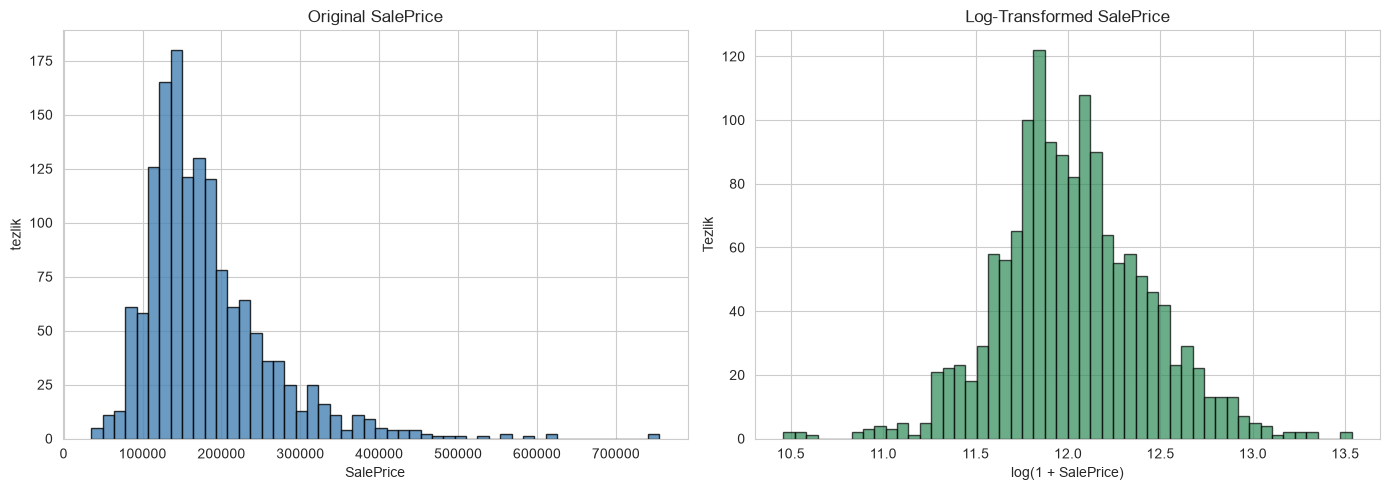

In [2]:
# TODO: Xüsusiyyət mühəndisliyi aparılmış təlim verilənlərini yükləyin
# - 'Solutions/train_feature_engineered.csv' faylını yükləmək üçün pd.read_csv() istifadə edin
# - 'df' dəyişənində saxlayın
# - Ölçünü (shape) çap edin

df = pd.read_csv('train_feature_engineered.csv')
print(df.shape)

# TODO: Xüsusiyyətləri və hədəfi ayırın
# - X = df.drop('SalePrice', axis=1)
# - y_raw = df['SalePrice']  (sonradan müqayisə üçün xam qiymətləri saxlayın)

X = df.drop("SalePrice" , axis= 1)
y_raw = df['SalePrice']

# TODO: Hədəfi loqarifmik transformasiya edin
# - y = np.log1p(y_raw)  (bu, log(1 + qiymət) hesablayır)
# - Fərqi görmək üçün y_raw.describe() ilə y.describe()-ı çap edin

y = np.log1p(y_raw)
y_raw.describe()
y.describe()


# TODO: Transformasiyanı vizuallaşdırın
# - 1x2 subplot yaradın
# - Sol: y_raw histoqramı, başlıq 'Original SalePrice'
# - Sağ: y histoqramı, başlıq 'Log-Transformed SalePrice'
# - Diqqət edin, sağ qrafik daha simmetrikdir (normal formalıdır)

fig, axes = plt.subplots(1 ,2 , figsize=(14,5))

axes[0].hist(y_raw , bins=50 , color = 'steelblue' , edgecolor = 'black' , alpha = 0.8)
axes[0].set_title("Original SalePrice")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("tezlik")

axes[1].hist(y, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
axes[1].set_title('Log-Transformed SalePrice')
axes[1].set_xlabel('log(1 + SalePrice)')
axes[1].set_ylabel('Tezlik')

plt.tight_layout()
plt.show()





---
## Tapşırıq 3: Xüsusiyyətlərin Modelləşdirmə üçün Ön İşlənməsi

Modelləri öyrətməzdən əvvəl bizə lazımdır:
1. Qalan kateqorial sütunları idarə etmək (onları one-hot kodlaşdırmaq)
2. `Id` sütununu silmək (o, xüsusiyyət deyil)
3. Çatışmayan dəyərləri doldurmaq
4. Reqlyarizasiyalı xətti modellər üçün xüsusiyyətləri miqyaslamaq


In [3]:
# TODO: Id sütunu varsa, silin
# - if 'Id' in X.columns: X = X.drop('Id', axis=1)

if "ID" in X.columns:
    X = X.drop("Id" , axis=1)

# TODO: Kateqorial sütunları müəyyən edin
# - cat_cols = X.select_dtypes(include=['object']).columns.tolist()
# - Neçə kateqorial sütunun qaldığını çap edin
# - Onların adlarını çap edin

cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"Kateqorial sütunların sayı: {len(cat_cols)} ")
print(f"Adları: {cat_cols}")


# TODO: Kateqorial sütunları one-hot kodlaşdırın
# - X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
# - Kodlaşdırmadan sonra yeni ölçünü çap edin

X = pd.get_dummies(X , columns=cat_cols , drop_first=True)
print(f"Kodlaşdırmadan sonra ölçü: {X.shape}")

# TODO: Qalan çatışmayan dəyərləri 0 ilə doldurun
# - X = X.fillna(0)
# - Yoxlayın: X.isnull().sum().sum() çap edin (0 olmalıdır)

X = X.fillna(0)

print(f"Çatışmayan dəyərlərin sayı: {X.isnull().sum().sum()}")   # 0 olmalıdır

print(f"Yekun xüsusiyyət sayı: {X.shape[1]}")
# TODO: Yekun xüsusiyyət sayını çap edin


Kateqorial sütunların sayı: 35 
Adları: ['MSSubClass', 'MSZoning', 'LotShape', 'LandContour', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'BldgType', 'HouseStyle', 'RoofStyle', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']
Kodlaşdırmadan sonra ölçü: (1458, 250)
Çatışmayan dəyərlərin sayı: 0
Yekun xüsusiyyət sayı: 250


In [4]:
# TODO: Verilənləri təlim və test dəstlərinə bölün
# - İstifadə edin: X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# - Dörd dəstin ölçülərini çap edin

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)

# TODO: Xüsusiyyətləri miqyaslayın (Ridge, Lasso, ElasticNet üçün lazımdır)
# - scaler = StandardScaler()
# - X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
# - X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
# - Qeyd: təlim verilənləri üzərində fit edin, test verilənləri üzərində transform edin (heç vaxt test üzərində fit etməyin!)
# - Qeyd: ağac əsaslı modellər (RF, XGBoost, LightGBM) miqyaslamaya ehtiyac DUYMUR

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train) , columns = X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test) , columns= X_test.columns)

---
## Tapşırıq 4: Çarpaz Yoxlama (Cross-Validation) Çərçivəsinin Qurulması

### Tək train/test bölgüsü əvəzinə niyə çarpaz yoxlama?

Tək 80/20 bölgüsü tələbəni yalnız bir imtahanla qiymətləndirmək kimidir — ona şans gələ də bilər, gəlməyə də. **5-Qat Çarpaz Yoxlama (5-Fold Cross-Validation)** verilənləri 5 hissəyə bölür, 5 dəfə öyrədir (hər dəfə fərqli hissəni kənarda saxlayır) və nəticələrin ortalamasını alır. Bu, modelin Kaggle-da necə performans göstərəcəyinə dair daha etibarlı qiymətləndirmə verir.

```
Qat 1:   [TEST] [Təlim] [Təlim] [Təlim] [Təlim]  → Nəticə 1
Qat 2:   [Təlim] [TEST] [Təlim] [Təlim] [Təlim]  → Nəticə 2
Qat 3:   [Təlim] [Təlim] [TEST] [Təlim] [Təlim]  → Nəticə 3
Qat 4:   [Təlim] [Təlim] [Təlim] [TEST] [Təlim]  → Nəticə 4
Qat 5:   [Təlim] [Təlim] [Təlim] [Təlim] [TEST]  → Nəticə 5

Yekun Nəticə = Ortalama(Nəticə 1..5)  ±  Std(Nəticə 1..5)
```


In [5]:
# TODO: K-Fold çarpaz yoxlamanı qurun
# - kf = KFold(n_splits=5, shuffle=True, random_state=42)
kf = KFold(n_splits=5 , shuffle=True , random_state=42)


# TODO: Modelləri çarpaz yoxlama ilə qiymətləndirmək üçün köməkçi funksiya yaradın
# def rmse_cv(model, X, y):
#     scores = cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv=kf)
#     return -scores  (mənfi işarəni çevirin, çünki sklearn mənfi RMSE qaytarır)

def rmse_cv(model , X , y):
    scores = cross_val_score(model , X , y , scoring='neg_root_mean_squared_error' , cv=kf)
    return -scores

# İstifadə: scores = rmse_cv(model, X_train_scaled, y_train)
#        print(f"RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")


# TODO: Bütün modellərin nəticələrini saxlamaq üçün lüğət (dictionary) yaradın
# - results = {}  (hər modeli öyrətdikcə bunu dolduracağıq)

# TODO: Təsdiq mesajı çap edin


---
## Tapşırıq 5: Reqlyarizasiyalı Xətti Modellər — Ridge, Lasso, ElasticNet

### Adi Xətti Reqressiyada nə səhv getdi?

Xətti Reqressiya yalnız proqnoz xətasını (MSE) minimuma endirir. 200+ xüsusiyyətlə onun çox azadlığı var — səs-küylü xüsusiyyətlərə böyük əmsallar verir və overfitting edir.

**Reqlyarizasiya (Regularization)** modeli əmsalları kiçik saxlamağa məcbur edən cərimə həddi əlavə edir:

### Ridge (L2 Reqlyarizasiyası)

$$\text{Loss} = \text{MSE} + \alpha \sum_{j=1}^{p} \beta_j^2$$

- Cərimə olaraq **əmsalların kvadratlarının cəmini** əlavə edir
- Bütün əmsalları sıfıra doğru kiçildir, lakin heç vaxt tam sıfır etmir
- Çoxlu xüsusiyyətin hər biri bir az töhfə verdikdə yaxşıdır
- `alpha` cərimənin gücünü idarə edir: alpha nə qədər yüksəkdirsə, əmsallar bir o qədər kiçikdir

### Lasso (L1 Reqlyarizasiyası)

$$\text{Loss} = \text{MSE} + \alpha \sum_{j=1}^{p} |\beta_j|$$

- Cərimə olaraq **əmsalların mütləq qiymətlərinin cəmini** əlavə edir
- Əmsalları tam sıfıra qədər kiçildə bilər — avtomatik xüsusiyyət seçimi
- Yalnız bir neçə xüsusiyyət həqiqətən vacib olduqda yaxşıdır
- 200+ xüsusiyyətlə Lasso, çox güman ki, onların 100+-ını sıfırlayacaq

### ElasticNet (L1 + L2 Birləşməsi)

$$\text{Loss} = \text{MSE} + \alpha \left( r \sum |\beta_j| + \frac{1-r}{2} \sum \beta_j^2 \right)$$

- Ridge və Lasso-nu birləşdirir: `l1_ratio` (r) qarışığı idarə edir
- `l1_ratio=1.0` → saf Lasso, `l1_ratio=0.0` → saf Ridge
- Xüsusiyyətlər bir-biri ilə korrelyasiya etdikdə yaxşıdır (Lasso tək başına korrelyasiya edən qrupdan təsadüfi birini seçə bilər)


In [6]:
# ===========================================================
# Addım 5.1: Baza Xətti — Adi Xətti Reqressiya (Mərhələ 5-dəki yanaşmamız)
# ===========================================================

# TODO: Adi Xətti Reqressiya modelini öyrədin
# - lr = LinearRegression()
# - scores = rmse_cv(lr, X_train_scaled, y_train)
# - results['LinearRegression'] = scores
# - Çap edin: f"Linear Regression RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})"
# - Bu, keçməli olduğumuz baza xəttidir (baseline)

lr = LinearRegression()
scores = rmse_cv(lr , X_train_scaled , y_train)
results = {}
results['LinearRegression'] = scores
print(f"Linear Regression RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")



Linear Regression RMSE: 0.1216 (+/- 0.0141)


In [7]:
# ===========================================================
# Addım 5.2: Ridge Reqressiyası
# ===========================================================

# TODO: Ən yaxşısını tapmaq üçün Ridge-i müxtəlif alpha dəyərləri ilə öyrədin
# - alphas = [0.1, 1.0, 5.0, 10.0, 50.0, 100.0]
# - Hər alpha üçün:
#     ridge = Ridge(alpha=alpha)
#     scores = rmse_cv(ridge, X_train_scaled, y_train)
#     print(f"  alpha={alpha:>6}: RMSE = {scores.mean():.4f} (+/- {scores.std():.4f})")

alphas = [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 170.0 ,200.0,] 

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    scores = rmse_cv(ridge , X_train_scaled , y_train)
    print(f"alpha={alpha:>6}: RMSE = {scores.mean():.4f} (+/- {scores.std():.4f})")

# TODO: Ridge-i ən yaxşı alpha ilə öyrədin
# - best_ridge = Ridge(alpha=<best_alpha>)
# - scores = rmse_cv(best_ridge, X_train_scaled, y_train)
# - results['Ridge'] = scores
# - Ən yaxşı nəticəni çap edin

best_alpha = 200.0

best_ridge = Ridge(alpha=best_alpha)
scores = rmse_cv(best_ridge , X_train_scaled , y_train)
results["Ridge"] = scores
print(f"Ən yaxşı alpha: {best_alpha}")
print(f"Ridge RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

print(results.keys())

alpha=   0.1: RMSE = 0.1212 (+/- 0.0136)
alpha=   1.0: RMSE = 0.1198 (+/- 0.0123)
alpha=   5.0: RMSE = 0.1195 (+/- 0.0115)
alpha=  10.0: RMSE = 0.1197 (+/- 0.0113)
alpha=  50.0: RMSE = 0.1186 (+/- 0.0106)
alpha= 100.0: RMSE = 0.1171 (+/- 0.0103)
alpha= 170.0: RMSE = 0.1161 (+/- 0.0101)
alpha= 200.0: RMSE = 0.1159 (+/- 0.0101)
Ən yaxşı alpha: 200.0
Ridge RMSE: 0.1159 (+/- 0.0101)
dict_keys(['LinearRegression', 'Ridge'])


In [8]:
# ===========================================================
# Addım 5.3: Lasso Reqressiyası
# ===========================================================

# TODO: Lasso-nu müxtəlif alpha dəyərləri ilə öyrədin
# - alphas = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05]
# - Qeyd: Lasso, Ridge-dən daha kiçik alpha dəyərləri istifadə edir
# - Hər alpha üçün:
#     lasso = Lasso(alpha=alpha, max_iter=10000)
#     scores = rmse_cv(lasso, X_train_scaled, y_train)
#     print(f"  alpha={alpha}: RMSE = {scores.mean():.4f} (+/- {scores.std():.4f})")

lasso_alphas = [0.0001, 0.0005, 0.001, 0.002 , 0.003 , 0.004 ,0.005, 0.01, 0.05]
for alpha in lasso_alphas:
    lasso = Lasso(alpha=alpha , max_iter=10000)
    scores = rmse_cv(lasso , X_train_scaled , y_train)
    print(f"alpha={alpha}: RMSE = {scores.mean():.4f} (+/- {scores.std():.4f})")


# TODO: Lasso-nu ən yaxşı alpha ilə öyrədin
# - best_lasso = Lasso(alpha=<best_alpha>, max_iter=10000)
# - scores = rmse_cv(best_lasso, X_train_scaled, y_train)
# - results['Lasso'] = scores
# - Ən yaxşı nəticəni çap edin

best_alpha = 0.003

best_lasso = Lasso(alpha=best_alpha , max_iter=10000)
scores = rmse_cv(best_lasso , X_train_scaled , y_train)
results['Lasso'] = scores
print(f"Ən yaxşı alpha: {best_alpha}")
print(f"Lasso RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

# TODO: Lasso-nun neçə xüsusiyyəti sıfırladığını yoxlayın
# - best_lasso.fit(X_train_scaled, y_train)
# - n_zero = (best_lasso.coef_ == 0).sum()
# - print(f"Lasso zeroed out {n_zero} of {len(best_lasso.coef_)} features")
# - Bu, avtomatik xüsusiyyət seçimidir

best_lasso.fit(X_train_scaled , y_train)
n_zero = (best_lasso.coef_ == 0).sum()
print(f"Lasso zeroed out {n_zero} of {len(best_lasso.coef_)} features")

alpha=0.0001: RMSE = 0.1183 (+/- 0.0116)
alpha=0.0005: RMSE = 0.1166 (+/- 0.0106)
alpha=0.001: RMSE = 0.1156 (+/- 0.0098)
alpha=0.002: RMSE = 0.1133 (+/- 0.0097)
alpha=0.003: RMSE = 0.1127 (+/- 0.0097)
alpha=0.004: RMSE = 0.1128 (+/- 0.0097)
alpha=0.005: RMSE = 0.1133 (+/- 0.0097)
alpha=0.01: RMSE = 0.1179 (+/- 0.0099)
alpha=0.05: RMSE = 0.1483 (+/- 0.0112)
Ən yaxşı alpha: 0.003
Lasso RMSE: 0.1127 (+/- 0.0097)
Lasso zeroed out 146 of 250 features


In [9]:
# ===========================================================
# Addım 5.4: ElasticNet
# ===========================================================

# TODO: ElasticNet-i müxtəlif alpha və l1_ratio kombinasiyaları ilə öyrədin
# - alphas = [0.0001, 0.0005, 0.001, 0.005]
# - l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
# - Hər kombinasiya üçün:
#     enet = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=10000)
#     scores = rmse_cv(enet, X_train_scaled, y_train)
#     Nəticələri saxlayın və çap edin

# TODO: ElasticNet-i ən yaxşı alpha və l1_ratio ilə öyrədin
# - best_enet = ElasticNet(alpha=<best_alpha>, l1_ratio=<best_l1_ratio>, max_iter=10000)
# - scores = rmse_cv(best_enet, X_train_scaled, y_train)
# - results['ElasticNet'] = scores
# - Ən yaxşı nəticəni çap edin

enet_alphas = [0.0001, 0.0005, 0.001, 0.005]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
enet_results = {}

for alpha in enet_alphas:
    for l1_ratio in l1_ratios:
        enet = ElasticNet(alpha=alpha , l1_ratio=l1_ratio , max_iter=10000)
        scores = rmse_cv(enet , X_train_scaled , y_train)
        print(f"alpha={alpha:<7} l1_ratio={l1_ratio}: RMSE = {scores.mean():.4f} (+/- {scores.std():.4f})")

best_alpha = 0.005
best_l1_ratio = 0.7

best_enet = ElasticNet(alpha=best_alpha , l1_ratio=best_l1_ratio , max_iter = 10000)
scores = rmse_cv(best_enet, X_train_scaled, y_train)
results['ElasticNet'] = scores
print(f"Ən yaxşı alpha: {best_alpha}, l1_ratio: {best_l1_ratio}")
print(f"ElasticNet RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")



alpha=0.0001  l1_ratio=0.1: RMSE = 0.1206 (+/- 0.0131)
alpha=0.0001  l1_ratio=0.3: RMSE = 0.1197 (+/- 0.0124)
alpha=0.0001  l1_ratio=0.5: RMSE = 0.1192 (+/- 0.0121)
alpha=0.0001  l1_ratio=0.7: RMSE = 0.1188 (+/- 0.0119)
alpha=0.0001  l1_ratio=0.9: RMSE = 0.1185 (+/- 0.0117)
alpha=0.0005  l1_ratio=0.1: RMSE = 0.1190 (+/- 0.0119)
alpha=0.0005  l1_ratio=0.3: RMSE = 0.1178 (+/- 0.0112)
alpha=0.0005  l1_ratio=0.5: RMSE = 0.1172 (+/- 0.0108)
alpha=0.0005  l1_ratio=0.7: RMSE = 0.1169 (+/- 0.0106)
alpha=0.0005  l1_ratio=0.9: RMSE = 0.1166 (+/- 0.0106)
alpha=0.001   l1_ratio=0.1: RMSE = 0.1182 (+/- 0.0114)
alpha=0.001   l1_ratio=0.3: RMSE = 0.1172 (+/- 0.0107)
alpha=0.001   l1_ratio=0.5: RMSE = 0.1167 (+/- 0.0106)
alpha=0.001   l1_ratio=0.7: RMSE = 0.1163 (+/- 0.0103)
alpha=0.001   l1_ratio=0.9: RMSE = 0.1159 (+/- 0.0099)
alpha=0.005   l1_ratio=0.1: RMSE = 0.1170 (+/- 0.0105)
alpha=0.005   l1_ratio=0.3: RMSE = 0.1142 (+/- 0.0096)
alpha=0.005   l1_ratio=0.5: RMSE = 0.1130 (+/- 0.0097)
alpha=0.00

---
## Tapşırıq 6: Random Forest

### Niyə ağac əsaslı modellər?

Xətti modellər verilənlərin içindən düz xətt (və ya hipermüstəvi) çəkir. Lakin ev qiymətləri düz xətlərə tabe deyil:
- OverallQual=10 olan ev OverallQual=5 olan evdən sadəcə "iki dəfə bahalı" deyil — 4 dəfə bahalı ola bilər
- 2 yataq otağı və 3 hamamı olan evin qiyməti "yataq otağı təsiri" + "hamam təsiri" cəmindən fərqlidir

**Qərar Ağacları (Decision Trees)** bunu verilənləri bölgələrə ayırmaqla həll edir:
```
ƏGƏR OverallQual >= 7 VƏ GrLivArea >= 2000:
    $350,000 proqnozlaşdır (oxşar evlərin ortalaması)
ƏKS HALDA ƏGƏR OverallQual >= 7 VƏ GrLivArea < 2000:
    $250,000 proqnozlaşdır
ƏKS HALDA:
    $150,000 proqnozlaşdır
```

**Random Forest** hər biri təsadüfi verilən və xüsusiyyət alt çoxluğu üzərində olmaqla çoxlu ağac (məsələn, 500) öyrədir, sonra onların proqnozlarının ortalamasını alır. Bu, overfitting-i kəskin şəkildə azaldır.

### Əsas parametrlər:

- **`n_estimators`**: Ağacların sayı. Daha çox ağac = daha sabit proqnozlar (lakin daha yavaş). 500-1000 tipik dəyərdir.
- **`max_depth`**: Hər ağacın nə qədər dərinə böyüyə biləcəyi. Daha dərin = daha mürəkkəb qanunauyğunluqlar, lakin overfitting riski. `None` ağacların tam böyüməsinə imkan verir.
- **`min_samples_leaf`**: Yarpaq düyünündə (leaf node) minimum nümunə sayı. Daha yüksək = daha mühafizəkar ağaclar.
- **`max_features`**: Hər ağacın hər bölünmədə neçə xüsusiyyəti nəzərə aldığı. `'sqrt'` √(ümumi xüsusiyyətlər) deməkdir — müxtəlifliyi təmin edir.

**Qeyd:** Random Forest xüsusiyyətlərin miqyaslanmasına ehtiyac DUYMUR. Ağaclar hədd dəyərləri (threshold) üzrə bölür, ona görə dəyərlərin böyüklüyünün əhəmiyyəti yoxdur.


In [10]:
# TODO: Random Forest modelini öyrədin
# - rf = RandomForestRegressor(
#       n_estimators=500,      # 500 ağac
#       max_depth=None,        # ağaclar tam böyüsün
#       min_samples_leaf=2,    # hər yarpaqda ən azı 2 nümunə
#       max_features='sqrt',   # hər bölünmədə sqrt(n_features) istifadə et
#       random_state=42,
#       n_jobs=-1              # sürət üçün bütün CPU nüvələrindən istifadə et
#   )

param_grid = {
    'max_features' : ['sqrt' , 0.3 , 0.5],
    'min_samples_leaf' :[1 , 2 , 4],
    'max_depth' : [None , 15 , 25],
}

grid = GridSearchCV(
    RandomForestRegressor(n_estimators=500 , random_state=42 , n_jobs=-1),
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=kf,
    verbose=1
)

grid.fit(X_train , y_train)
print("Ən yaxşı parametrlər:", grid.best_params_)
print(f"Ən yaxşı CV RMSE: {-grid.best_score_:.4f}")
# TODO: Çarpaz yoxlama ilə qiymətləndirin
# - Qeyd: X_train istifadə edin (miqyaslanmamış!) — ağaclar miqyaslamaya ehtiyac duymur
# - scores = rmse_cv(rf, X_train, y_train)
# - results['RandomForest'] = scores
# - Çap edin: f"Random Forest RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})"




Fitting 5 folds for each of 27 candidates, totalling 135 fits
Ən yaxşı parametrlər: {'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 2}
Ən yaxşı CV RMSE: 0.1242


In [11]:
best_rf = grid.best_estimator_
scores = rmse_cv(best_rf , X_train , y_train)
results['RandomForest'] = scores
print(f"Random Forest RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

Random Forest RMSE: 0.1242 (+/- 0.0094)


---
## Tapşırıq 7: XGBoost (Extreme Gradient Boosting)

### XGBoost Random Forest-dən nə ilə fərqlənir?

**Random Forest**: Ağacları paralel şəkildə **müstəqil** öyrədir, sonra onların ortalamasını alır.

**XGBoost**: Ağacları **ardıcıl** öyrədir — hər yeni ağac əvvəlki bütün ağacların səhvlərini düzəltməyə diqqət yetirir.

Bunu belə təsəvvür edin:
1. Ağac 1 ev qiymətlərini proqnozlaşdırır → bəzilərini yanlış tapır
2. Ağac 2, Ağac 1-in **xətaları** üzərində öyrədilir → bəzi səhvləri düzəldir
3. Ağac 3 **qalan xətalar** üzərində öyrədilir → daha çoxunu düzəldir
4. 3000 raunddan sonra birləşmiş proqnoz çox dəqiq olur

Bu, AdaBoost ilə eyni boosting ideyasıdır (Mərhələ 6 Ansambl Öyrənməsindən), lakin XGBoost daha ağıllı riyaziyyatdan (ikinci dərəcəli qradiyent optimallaşdırması) istifadə edir və daha sürətlidir.

### Əsas parametrlər:

- **`n_estimators`**: Boosting raundlarının (ağacların) sayı. Daha çox raund = daha yaxşı, lakin overfitting-in qarşısını almaq üçün `early_stopping` istifadə edin.
- **`learning_rate`**: Hər ağacın nə qədər töhfə verdiyi. Daha aşağı (0.01-0.05) = daha çox ağac lazımdır, lakin daha yaxşı ümumiləşdirir.
- **`max_depth`**: Ağacın dərinliyi. Boosting Random Forest-dən daha dayaz ağaclar (3-6) istifadə edir.
- **`subsample`**: Hər ağac üçün istifadə olunan verilənlərin payı (0.7 = 70%). Təsadüfilik overfitting-in qarşısını alır.
- **`colsample_bytree`**: Hər ağac üçün istifadə olunan xüsusiyyətlərin payı. Random Forest-in `max_features` parametri ilə eyni ideyadır.
- **`reg_alpha`** (L1) və **`reg_lambda`** (L2): Yarpaq çəkilərinə reqlyarizasiya — Lasso/Ridge ilə eyni ideya, lakin hər ağacın daxilində tətbiq olunur.


In [12]:
# TODO: XGBoost modelini öyrədin
# - xgb = XGBRegressor(
#       n_estimators=3000,          # 3000-ə qədər boosting raundu
#       learning_rate=0.05,         # diqqətli öyrənmə üçün kiçik öyrənmə sürəti
#       max_depth=4,                # orta dərəcədə dayaz ağaclar
#       subsample=0.7,              # hər ağac üçün verilənlərin 70%-ni istifadə et
#       colsample_bytree=0.7,       # hər ağac üçün xüsusiyyətlərin 70%-ni istifadə et
#       reg_alpha=0.1,              # L1 reqlyarizasiyası
#       reg_lambda=1.0,             # L2 reqlyarizasiyası
#       random_state=42,
#       n_jobs=-1,
#       verbosity=0                 # təlim çıxışını gizlət
#   )

xgb = XGBRegressor(
    n_estimators = 3000,
    learning_rate = 0.05 , 
    max_depth = 4 ,
    subsample = 0.7,
    colsample_bytree = 0.7 , 
    reg_alpha = 0.1 , 
    reg_lambda = 1.0 , 
    random_state = 42, 
    n_jobs = -1 , 
    verbosity = 0
)

# TODO: Çarpaz yoxlama ilə qiymətləndirin
# - Qeyd: X_train istifadə edin (miqyaslanmamış!) — ağaclar miqyaslamaya ehtiyac duymur
# - scores = rmse_cv(xgb, X_train, y_train)
# - results['XGBoost'] = scores
# - Çap edin: f"XGBoost RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})"

scores = rmse_cv(xgb, X_train, y_train)
results['XGBoost'] = scores
print(f"XGBoost RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

XGBoost RMSE: 0.1183 (+/- 0.0090)


In [13]:
param_grid = {
    'n_estimators': [500, 100 , 1500 , 2000 , 3000],
    'learning_rate': [0.01, 0.03, 0.05],
    'max_depth': [3, 4 ,5],
    'colsample_bytree': [ 0.2 , 0.3],
} 

grid_XGB = GridSearchCV(
    XGBRegressor(subsample=0.8, random_state=42, n_jobs=-1),
    param_grid, scoring='neg_root_mean_squared_error', cv=kf, verbose=1
)

grid_XGB.fit(X_train, y_train)
print(grid_XGB.best_params_, -grid_XGB.best_score_)


Fitting 5 folds for each of 90 candidates, totalling 450 fits
{'colsample_bytree': 0.2, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 3000} 0.1116998469796121


In [14]:
best_xgb = grid_XGB.best_estimator_

scores = rmse_cv(best_xgb , X_train , y_train)
results['XGBoost_tuned'] = scores 

print(f"XGBoost (tuned) RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

XGBoost (tuned) RMSE: 0.1117 (+/- 0.0105)


---
## Tapşırıq 8: LightGBM (Light Gradient Boosting Machine)

### LightGBM XGBoost-dan nə ilə fərqlənir?

Hər ikisi qradiyent boosting üsuludur, lakin LightGBM iki əsas yenilikdən istifadə edir:

1. **Yarpaq üzrə böyümə (leaf-wise)** (XGBoost-un səviyyə üzrə - level-wise - böyüməsinə qarşı): Bütün yarpaqları eyni dərinlikdə böyütmək əvəzinə, LightGBM xətanı ən çox azaldan yarpağı böyüdür. Bu, daha az yarpaqla daha yaxşı dəqiqliyə çatır.

```
XGBoost (level-wise):         LightGBM (leaf-wise):
       O                            O
      / \                          / \
     O   O     (hamısı eyni dərinlikdə)   O   O
    / \  / \                     / \
   O  O O  O                    O   O   (ən çox fayda verdiyi yerdə ən dərinə böyüyür)
```

2. **Histoqram əsaslı bölünmə**: Hər mümkün bölünmə nöqtəsini yoxlamaq əvəzinə, LightGBM xüsusiyyət dəyərlərini qutulara (histoqramlara) qruplaşdırır. Bu, onu böyük verilənlər dəstlərində XGBoost-dan 10-20 dəfə sürətli edir.

### Əsas parametrlər:

- **`n_estimators`**: Boosting raundlarının sayı.
- **`learning_rate`**: Addım ölçüsünün kiçildilməsi. XGBoost-dakı ilə eyni rol.
- **`num_leaves`**: Ağac başına maksimum yarpaq sayı. Mürəkkəbliyi idarə edir (defolt: 31). Daha çox yarpaq = daha mürəkkəb.
- **`max_depth`**: Maksimum ağac dərinliyi. Məhdudiyyət olmaması üçün -1 təyin edin (əvəzinə `num_leaves` ilə idarə olunur).
- **`subsample`** və **`colsample_bytree`**: XGBoost-dakı ilə eyni təsadüfilik idarəetmələri.
- **`reg_alpha`** və **`reg_lambda`**: L1/L2 reqlyarizasiyası.


In [15]:
# TODO: LightGBM modelini öyrədin
# - lgbm = LGBMRegressor(
#       n_estimators=3000,          # 3000-ə qədər boosting raundu
#       learning_rate=0.05,         # kiçik öyrənmə sürəti
#       num_leaves=31,              # defolt, ağacın mürəkkəbliyini idarə edir
#       max_depth=4,                # dərinliyi məhdudlaşdır
#       subsample=0.7,              # hər ağac üçün verilənlərin 70%-ni istifadə et
#       colsample_bytree=0.7,       # hər ağac üçün xüsusiyyətlərin 70%-ni istifadə et
#       reg_alpha=0.1,              # L1 reqlyarizasiyası
#       reg_lambda=1.0,             # L2 reqlyarizasiyası
#       random_state=42,
#       n_jobs=-1,
#       verbosity=-1                # təlim çıxışını gizlət
#   )


lgbm = LGBMRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=31 , 
    max_depth=4 , 
    subsample=0.7 , 
    colsample_bytree=0.7 , 
    reg_alpha= 0.1 , 
    reg_lambda=1.0 , 
    random_state=42 , 
    n_jobs=-1 , 
    verbosity = -1 
)


# TODO: Çarpaz yoxlama ilə qiymətləndirin
# - Qeyd: X_train istifadə edin (miqyaslanmamış!) — ağaclar miqyaslamaya ehtiyac duymur
# - scores = rmse_cv(lgbm, X_train, y_train)
# - results['LightGBM'] = scores
# - Çap edin: f"LightGBM RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})"



scores = rmse_cv(lgbm , X_train , y_train)
results['LightGBM'] = scores
print(f"LightGBM RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")


LightGBM RMSE: 0.1212 (+/- 0.0097)


In [16]:
param_grid = {
    'n_estimators': [2000 , 3000 , 4000],
    'learning_rate': [0.01, 0.03],
    'num_leaves': [4, 8, 16],
    'max_depth': [2 , 3 , 4],
    'min_child_samples': [10, 20 , 30],
}

grid_lgb = GridSearchCV(
    LGBMRegressor(subsample=0.7 , subsample_freq=1 , random_state=42 , n_jobs=-1 ,colsample_bytree=0.7,
                reg_alpha= 0.1 , reg_lambda=1.0 ),scoring = 'neg_root_mean_squared_error' , verbose= 1 ,cv = kf, param_grid= param_grid)

grid_lgb.fit(X_train , y_train)
print(grid_lgb.best_params_ , -grid_lgb.best_score_)

results['LightGBM_tuned'] = rmse_cv(grid_lgb.best_estimator_, X_train, y_train)



Fitting 5 folds for each of 162 candidates, totalling 810 fits
{'learning_rate': 0.01, 'max_depth': 3, 'min_child_samples': 10, 'n_estimators': 4000, 'num_leaves': 4} 0.11303261161475202


In [17]:
s = results['LightGBM_tuned']
print(f"LightGBM(tuned) RMSE: {s.mean():.4f} (+/- {s.std():.4f})")

LightGBM(tuned) RMSE: 0.1130 (+/- 0.0092)


---
## Tapşırıq 9: Bütün Modellərin Müqayisəsi

İndi görək hansı modellər ən yaxşı nəticə göstərdi və niyə.

           Model  Mean RMSE  Std RMSE
   XGBoost_tuned     0.1117    0.0105
           Lasso     0.1127    0.0097
      ElasticNet     0.1128    0.0097
  LightGBM_tuned     0.1130    0.0092
           Ridge     0.1159    0.0101
         XGBoost     0.1183    0.0090
        LightGBM     0.1212    0.0097
LinearRegression     0.1216    0.0141
    RandomForest     0.1242    0.0094


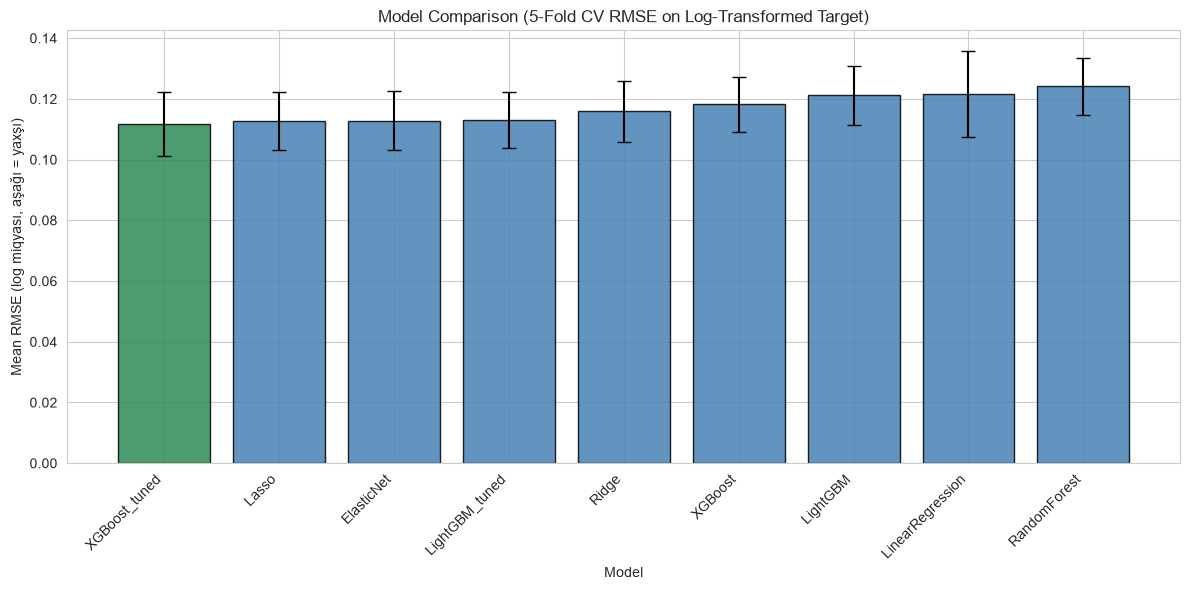

Model        XGBoost_tuned
Mean RMSE           0.1117
Std RMSE          0.010541
Name: 0, dtype: object

Qalib : XGBoost_tuned 
Mean RMSE: 0.1117 (+/- 0.0105)


In [18]:
# TODO: Müqayisə cədvəli yaradın
# - comparison = pd.DataFrame({
#       'Model': results.keys(),
#       'Mean RMSE': [scores.mean() for scores in results.values()],
#       'Std RMSE': [scores.std() for scores in results.values()]
#   })
# - comparison = comparison.sort_values('Mean RMSE')
# - Müqayisə cədvəlini çap edin

comparison = pd.DataFrame({
    'Model' : results.keys(),
    'Mean RMSE' : [scores.mean() for scores in results.values()] , 
    'Std RMSE' : [scores.std() for scores in results.values()]
})


comparison = comparison.sort_values('Mean RMSE' , ascending=True).reset_index(drop=True)
print(comparison.round(4).to_string(index=False))

comparison.head(10)
# TODO: Modellərin müqayisəsini vizuallaşdırın
# - x oxunda model adları, y oxunda Mean RMSE olan bar plot yaradın
# - Std RMSE istifadə edərək xəta çubuqları (error bars) əlavə edin
# - Ən yaxşı modeli fərqli rənglə göstərin
# - Başlıq əlavə edin: 'Model Comparison (5-Fold CV RMSE on Log-Transformed Target)'
# - Daha aşağı RMSE = daha yaxşı

fig , axes = plt.subplots(figsize=(12,6))
colors = ['seagreen' if i == 0 else 'steelblue' for i in range(len(comparison))]
axes.bar(comparison['Model'] , comparison['Mean RMSE'] , yerr = comparison['Std RMSE'], capsize=5, 
        color= colors , edgecolor = 'black' , alpha = 0.85)

axes.set_title('Model Comparison (5-Fold CV RMSE on Log-Transformed Target)')
axes.set_xlabel('Model')
axes.set_ylabel('Mean RMSE (log miqyası, aşağı = yaxşı)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# TODO: Qalibi çap edin
# - Ən aşağı Mean RMSE-yə malik modeli çap edin

best = comparison.iloc[0]
print(best)
print(f"\nQalib : {best['Model']} ")
print(f"Mean RMSE: {best['Mean RMSE']:.4f} (+/- {best['Std RMSE']:.4f})")

=== Xətti modellər (miqyaslanmış) ===
LinearRegression   RMSE: 0.1301 R²: 0.8996
Ridge              RMSE: 0.1261 R²: 0.9057
Lasso              RMSE: 0.1204 R²: 0.9140
ElasticNet         RMSE: 0.1203 R²: 0.9141

=== Ağac modelləri (miqyaslanmamış) ===
RandomForest       RMSE: 0.1306 R²: 0.8989
XGBoost            RMSE: 0.1240 R²: 0.9087
XGBoost_tuned      RMSE: 0.1186 R²: 0.9166
LightGBM           RMSE: 0.1277 R²: 0.9032
LightGBM_tuned     RMSE: 0.1198 R²: 0.9149


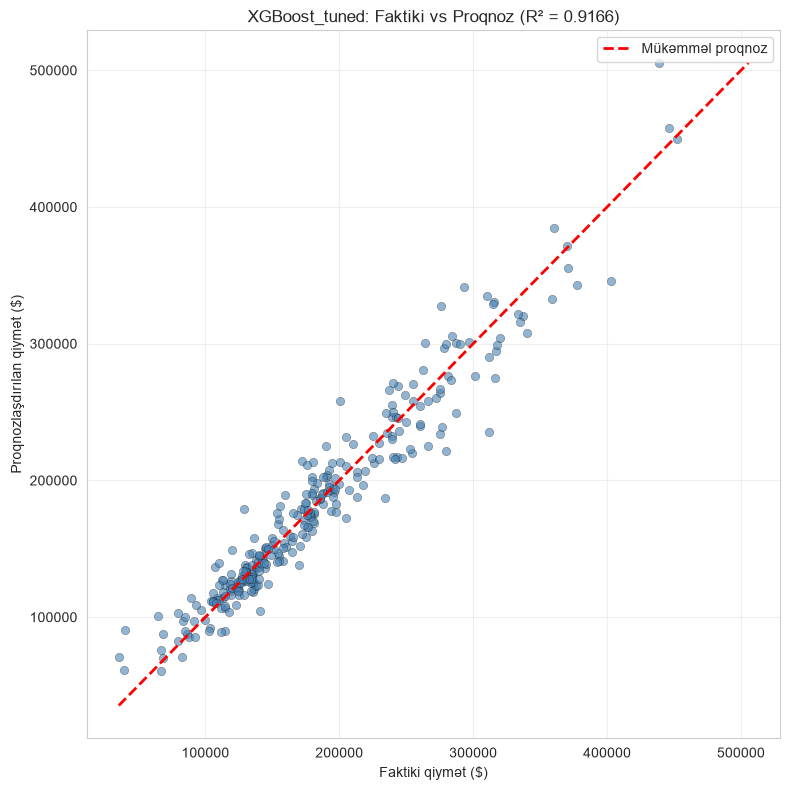

In [19]:
# TODO: Bütün modelləri tam təlim dəsti üzərində öyrədin və ayrılmış test dəstində qiymətləndirin

# Hər model üçün test dəstindəki faktiki RMSE-ni görmək istəyirik:

# - Xətti modellər üçün (miqyaslanmış verilənlərdən istifadə edin): X_train_scaled, X_test_scaled
# - Ağac modelləri üçün (miqyaslanmamış verilənlərdən istifadə edin): X_train, X_test

linear_models = {
    'LinearRegression' : lr,
    'Ridge' : best_ridge,
    'Lasso' : best_lasso,
    'ElasticNet' : best_enet,
}

tree_models = {
    'RandomForest': best_rf,
    'XGBoost': xgb,
    'XGBoost_tuned': best_xgb,
    'LightGBM': lgbm,
    'LightGBM_tuned': grid_lgb.best_estimator_,
}

test_results = {}

def qiymetlendirmek(models , Xtrain , Xtest) :
    for name , model in models.items():
        model.fit(Xtrain , y_train)
        y_pred = model.predict(Xtest)
        rmse = np.sqrt(mean_squared_error(y_test , y_pred))
        r2 = r2_score(y_test, y_pred)
        test_results[name] = (rmse, r2, y_pred)
        print(f"{name:<18} RMSE: {rmse:.4f} R²: {r2:.4f}")

print("=== Xətti modellər (miqyaslanmış) ===")
qiymetlendirmek(linear_models, X_train_scaled, X_test_scaled)
print("\n=== Ağac modelləri (miqyaslanmamış) ===")
qiymetlendirmek(tree_models , X_train , X_test)


# TODO: Hər model üçün:
# - model.fit(X_train_appropriate, y_train)
# - y_pred = model.predict(X_test_appropriate)
# - rmse = np.sqrt(mean_squared_error(y_test, y_pred))
# - r2 = r2_score(y_test, y_pred)
# - Modelin adını, RMSE və R² qiymətlərini çap edin

# TODO: Ən yaxşı model üçün Faktiki və Proqnozlaşdırılan scatter plot yaradın
# - Proqnozları dollar qiymətlərinə çevirin: np.expm1(y_pred)
# - Faktiki dəyərləri geri çevirin: np.expm1(y_test)
# - Diaqonal xətli scatter plot
# - Başlıqda modelin adı və R² qiyməti
best_name = comparison.iloc[0]['Model']
best_rmse, best_r2, best_pred = test_results[best_name]

actual_usd = np.expm1(y_test)
pred_usd = np.expm1(best_pred)


plt.figure(figsize=(8,8))
plt.scatter(actual_usd , pred_usd , alpha=0.6 , edgecolors='k' , linewidths=0.3  , color = 'steelblue')
lims = [min(actual_usd.min(), pred_usd.min()),
        max(actual_usd.max(), pred_usd.max())]

plt.plot(lims, lims, 'r--', lw=2, label='Mükəmməl proqnoz')
plt.xlabel('Faktiki qiymət ($)')
plt.ylabel('Proqnozlaşdırılan qiymət ($)')
plt.title(f'{best_name}: Faktiki vs Proqnoz (R² = {best_r2:.4f})')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Tapşırıq 10: Ən Yaxşı Modellərin Birləşdirilməsi (Blending)

### Blending niyə işləyir

Fərqli modellərin fərqli güclü tərəfləri var:
- **Lasso/Ridge**: Xətti meylləri tutmaqda yaxşıdır, görünməmiş verilənlərdə sabitdir
- **XGBoost/LightGBM**: Qeyri-xətti qanunauyğunluqları və qarşılıqlı təsirləri tutmaqda yaxşıdır

Onların proqnozlarının ortalamasını aldıqda, bir modelin xətaları digəri tərəfindən qismən ləğv olunur. Bu, demək olar ki, həmişə nəticəni yaxşılaşdırır.

**Sadə çəkili ortalama (weighted average)** ən asan və ən effektiv yanaşmadır:

$$\hat{y}_{\text{blend}} = w_1 \cdot \hat{y}_{\text{Ridge}} + w_2 \cdot \hat{y}_{\text{Lasso}} + w_3 \cdot \hat{y}_{\text{XGBoost}} + w_4 \cdot \hat{y}_{\text{LightGBM}}$$

burada $w_1 + w_2 + w_3 + w_4 = 1$

**İpucu:** Daha aşağı CV RMSE-yə malik modellərə daha çox çəki verin.


In [20]:
# TODO: Bütün modelləri tam təlim dəsti üzərində öyrədin
# - best_ridge.fit(X_train_scaled, y_train)
# - best_lasso.fit(X_train_scaled, y_train)
# - xgb.fit(X_train, y_train)
# - lgbm.fit(X_train, y_train)

# yuxarida fit olunub : men elastic net isdifade edeceyem. ridge daha pis netice gosdermisdir. 4 model isdifadesinde fit olunanlar :
# grid_XGB , grid_lgb , best_lasso , best_enet

best_enet.fit(X_train_scaled, y_train)

# TODO: Test dəstində hər modeldən proqnozlar əldə edin
# - pred_ridge = best_ridge.predict(X_test_scaled)
# - pred_lasso = best_lasso.predict(X_test_scaled)
# - pred_xgb = xgb.predict(X_test)
# - pred_lgbm = lgbm.predict(X_test)


pred_enet = best_enet.predict(X_test_scaled)
pred_lasso = best_lasso.predict(X_test_scaled)

pred_xgb = grid_XGB.predict(X_test)
pred_lgb = grid_lgb.predict(X_test)

# TODO: Proqnozları çəkilərlə birləşdirin
# - Bərabər çəkilərlə başlayın: hər biri 0.25
# - pred_blend = 0.25 * pred_ridge + 0.25 * pred_lasso + 0.25 * pred_xgb + 0.25 * pred_lgbm

pred_blend = 0.2 * pred_enet + 0.2 * pred_lasso + 0.3 * pred_xgb + 0.3 * pred_lgb

# TODO: Birləşdirilmiş proqnozu qiymətləndirin
# - rmse_blend = np.sqrt(mean_squared_error(y_test, pred_blend))
# - r2_blend = r2_score(y_test, pred_blend)
# - Çap edin: f"Blended RMSE: {rmse_blend:.4f}, R²: {r2_blend:.4f}"
# - Fərdi modellərin nəticələri ilə müqayisə edin

rmse_blend = np.sqrt(mean_squared_error(y_test, pred_blend))
r2_blend = r2_score(y_test, pred_blend)
print(f"Blended RMSE: {rmse_blend:.4f}, R²: {r2_blend:.4f}")

for name , pred in [('lasso' , pred_lasso) , ('ElasticNet', pred_enet),
                ('XGBoost_tuned', pred_xgb), ('LightGBM_tuned', pred_lgb),
                ('Blend', pred_blend)]:
    print(f"{name:15} RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.4f} | R²: {r2_score(y_test, pred):.4f}")


for w in [(0.25, 0.25, 0.25, 0.25), (0.15, 0.15, 0.40, 0.30), (0.10, 0.10, 0.45, 0.35), (0.20, 0.20, 0.30, 0.30)]:
    p = np.average([pred_enet, pred_lasso, pred_xgb, pred_lgb], axis=0, weights=w)
    print(f"{w}: RMSE = {np.sqrt(mean_squared_error(y_test, p)):.4f}")

Blended RMSE: 0.1166, R²: 0.9193
lasso           RMSE: 0.1204 | R²: 0.9140
ElasticNet      RMSE: 0.1203 | R²: 0.9141
XGBoost_tuned   RMSE: 0.1186 | R²: 0.9166
LightGBM_tuned  RMSE: 0.1198 | R²: 0.9149
Blend           RMSE: 0.1166 | R²: 0.9193
(0.25, 0.25, 0.25, 0.25): RMSE = 0.1168
(0.15, 0.15, 0.4, 0.3): RMSE = 0.1167
(0.1, 0.1, 0.45, 0.35): RMSE = 0.1170
(0.2, 0.2, 0.3, 0.3): RMSE = 0.1166


In [21]:
# TODO: Müxtəlif blending çəkiləri ilə təcrübə edin
# - Ən yaxşı performans göstərən modellərə daha çox çəki verməyə çalışın
# - Nümunə: 0.15 * ridge + 0.15 * lasso + 0.35 * xgb + 0.35 * lgbm

# TODO: Bir neçə çəki kombinasiyasını sınayın və birləşdirilmiş RMSE-ni izləyin
# - weight_configs = [
#     (0.25, 0.25, 0.25, 0.25),  # bərabər
#     (0.15, 0.15, 0.35, 0.35),  # ağac modellərinə üstünlük ver
#     (0.10, 0.10, 0.40, 0.40),  # ağaclara güclü üstünlük ver
#     (0.20, 0.20, 0.30, 0.30),  # ağaclara cüzi üstünlük
#   ]
# - Hər (w1, w2, w3, w4) üçün:
#     pred = w1*pred_ridge + w2*pred_lasso + w3*pred_xgb + w4*pred_lgbm
#     rmse = np.sqrt(mean_squared_error(y_test, pred))
#     print(f"Weights ({w1},{w2},{w3},{w4}): RMSE = {rmse:.4f}")

# TODO: Ən yaxşı çəki kombinasiyasını seçin və saxlayın
# - best_weights = (<w1>, <w2>, <w3>, <w4>)

weight_results = {'W1_elasticnet' : 0.2 , 'W2_Lasso' : 0.2 , 'W3_lgb' : 0.3 , 'W4_xgb': 0.3}


---
## Tapşırıq 11: Kaggle Təqdimatının Yaradılması

İndi Kaggle-ın gözlədiyi formatda real təqdimat faylı hazırlayaq:
```
Id,SalePrice
1461,169000.1
1462,187724.1
...
```

**Kritik addımlar:**
1. Test dəstinə tam eyni ön işləməni tətbiq edin
2. Proqnozları loqarifmik məkanda verin
3. Dollar qiymətlərini almaq üçün `np.expm1()` ilə tərs transformasiya edin
4. Mənfi proqnozları 0-a qədər kəsin (qiymətlər mənfi ola bilməz)


In [22]:
# TODO: Test verilənlərini yükləyin
# - test_df = pd.read_csv('Solutions/test_feature_engineered.csv')
# - test_ids = test_df['Id']  (təqdimat üçün ID-ləri saxlayın)
# - X_kaggle = test_df.drop('Id', axis=1, errors='ignore')
# - test_df.shape çap edin

test_df = pd.read_csv('test_feature_engineered.csv')
test_ids = test_df['Id']
X_kaggle = test_df.drop('Id', axis=1, errors='ignore')
print(f"test_df ölçüsü: {test_df.shape}")


# TODO: Təlimdəki ilə eyni ön işləməni tətbiq edin
# - Eyni sütunlarla one-hot kodlaşdırın:
#   X_kaggle = pd.get_dummies(X_kaggle, columns=cat_cols_from_training, drop_first=True)
# - Sütunları təlim dəsti ilə uyğunlaşdırın (çatışmayan sütunları 0 kimi əlavə edin, artıqları silin):
#   X_kaggle = X_kaggle.reindex(columns=X_train.columns, fill_value=0)
# - Çatışmayan dəyərləri doldurun: X_kaggle = X_kaggle.fillna(0)
# - Xətti modellər üçün miqyaslayın: X_kaggle_scaled = pd.DataFrame(scaler.transform(X_kaggle), columns=X_kaggle.columns)

# DİQQƏT 1: burada drop_first=True İSTİFADƏ ETMİRİK. Test dəstində bəzi kateqoriyalar yoxdur
# (məs. GarageQual-da 'Ex'), ona görə test üzərində drop_first "yanlış" səviyyəni silir və
# 76 test evi səssizcə səhv kodlaşır. Əvəzinə hamısını kodlaşdırıb reindex ilə təlimin sütunlarını seçirik
# (təlimdə drop_first ilə atılmış sütunlar reindex zamanı avtomatik silinir).
X_kaggle = pd.get_dummies(X_kaggle, columns=cat_cols)

# DİQQƏT 2: 7-ci xanada "ID" yazıldığı üçün 'Id' təlim xüsusiyyətlərinin içində qalıb.
# Model onu xüsusiyyət kimi öyrəndiyi üçün test-də də real Id qiymətləri olmalıdır (0 yox!).
# (7-ci xanada "ID" -> "Id" düzəldib hamısını yenidən işə salsanız, bu if avtomatik işləməyəcək, problem də olmayacaq.)
if 'Id' in X_train.columns:
    X_kaggle['Id'] = test_ids.values

X_kaggle = X_kaggle.reindex(columns=X_train.columns, fill_value=0)
X_kaggle = X_kaggle.fillna(0)

X_kaggle_scaled = pd.DataFrame(scaler.transform(X_kaggle), columns=X_kaggle.columns)


# TODO: Uyğunluğu yoxlamaq üçün ölçüləri çap edin
# - print(f"Training features: {X_train.shape[1]}")
# - print(f"Test features:     {X_kaggle.shape[1]}")
# - Bunlar üst-üstə düşməlidir!

print(f"Training features: {X_train.shape[1]}")
print(f"Test features:     {X_kaggle.shape[1]}")
print("Sütun adları və sırası eynidir:", list(X_kaggle.columns) == list(X_train.columns))
print("Test-də NaN sayı:", X_kaggle.isnull().sum().sum())
print("Test sətir sayı (1459 olmalıdır):", X_kaggle.shape[0], "| test_ids:", len(test_ids))

test_df ölçüsü: (1459, 82)
Training features: 250
Test features:     250
Sütun adları və sırası eynidir: True
Test-də NaN sayı: 0
Test sətir sayı (1459 olmalıdır): 1459 | test_ids: 1459


In [23]:
# TODO: Kaggle test dəstində birləşdirilmiş (blended) proqnozlar yaradın
# - Tapşırıq 10-dan ən yaxşı çəkilərdən istifadə edin
# - (w1, w2, w3, w4) = best_weights
# - pred_kaggle = (
#       w1 * best_ridge.predict(X_kaggle_scaled) +
#       w2 * best_lasso.predict(X_kaggle_scaled) +
#       w3 * xgb.predict(X_kaggle) +
#       w4 * lgbm.predict(X_kaggle)
#   )


pred_kaggle = (
    weight_results['W1_elasticnet'] * best_enet.predict(X_kaggle_scaled)+
    weight_results['W2_Lasso'] * best_lasso.predict(X_kaggle_scaled)+
    weight_results['W3_lgb'] * grid_XGB.predict(X_kaggle)+
    weight_results['W4_xgb'] * grid_lgb.predict(X_kaggle)
)

# TODO: Faktiki qiymətləri almaq üçün loqarifmik transformasiyanı tərs çevirin
# - final_predictions = np.expm1(pred_kaggle)
# - final_predictions = np.maximum(final_predictions, 0)  (mənfi dəyərləri 0-a qədər kəsin)

final_predictions = np.expm1(pred_kaggle)
final_predictions = np.maximum(final_predictions , 0)


# TODO: Təqdimat DataFrame-i yaradın
# - submission = pd.DataFrame({'Id': test_ids, 'SalePrice': final_predictions})
# - submission.head() çap edin
# - Qiymət aralığını yoxlamaq üçün submission.describe() çap edin

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': final_predictions})
print(submission.head())
print(submission.describe())

# TODO: Təqdimat faylını yadda saxlayın
# - submission.to_csv('submission_advanced.csv', index=False)
# - Təsdiq mesajını və fayl yolunu çap edin

submission.to_csv('submission_advanced.csv', index=False)
print("Təqdimat faylı saxlanıldı: submission_advanced.csv")

     Id      SalePrice
0  1461  117433.272438
1  1462  153935.860954
2  1463  182286.319930
3  1464  194114.787391
4  1465  193359.243967
                Id      SalePrice
count  1459.000000    1459.000000
mean   2190.000000  177741.560705
std     421.321334   79396.013443
min    1461.000000   51067.262909
25%    1825.500000  127175.749187
50%    2190.000000  155340.537950
75%    2554.500000  206917.284662
max    2919.000000  926112.015206
Təqdimat faylı saxlanıldı: submission_advanced.csv


---
## Tapşırıq 12: Xülasə və Refleksiya

### Nələri Öyrəndik

1. **SalePrice-ı loqarifmik transformasiya etmək** RMSLE-ni RMSE-yə çevirir və paylanmanı normallaşdırır
2. **Reqlyarizasiya** (Ridge, Lasso, ElasticNet) çoxlu xüsusiyyət olduqda əmsalların partlamasının qarşısını alır
3. **Lasso** əhəmiyyətsiz xüsusiyyətləri sıfırlayaraq avtomatik xüsusiyyət seçimi həyata keçirir
4. **Ağac əsaslı modellər** (Random Forest, XGBoost, LightGBM) xətti modellərin qaçırdığı qeyri-xətti qanunauyğunluqları tutur
5. **XGBoost və LightGBM** ardıcıl boosting istifadə edir — hər ağac əvvəlkinin səhvlərini düzəldir
6. **Çarpaz yoxlama** tək təsadüfi bölgüdən asılı olmayan etibarlı performans qiymətləndirməsi verir
7. **Modellərin birləşdirilməsi (blending)** fərqli modellərin güclü tərəflərini birləşdirir və demək olar ki, həmişə nəticəni yaxşılaşdırır

### Performans Sualları — Bunlara Cavab Verin:

1. **Yaxşılaşma**: Mərhələ 5-dəki Kaggle nəticəniz nə idi? Yeni nəticəniz nədir? Nə qədər yaxşılaşdı?

2. **Ən yaxşı tək model**: Çarpaz yoxlamada hansı tək model ən yaxşı nəticəni göstərdi? Sizcə niyə?

3. **Xətti və Ağac**: XGBoost/LightGBM Ridge/Lasso-dan nə qədər yaxşı idi? Bu, verilənlər haqqında sizə nə deyir?

4. **Blending faydası**: Blending ən yaxşı tək modeldən daha yaxşı nəticə verdimi? Nə qədər?

5. **Lasso ilə xüsusiyyət seçimi**: Lasso neçə xüsusiyyəti sıfırladı? Bu, verilənlər dəsti haqqında nəyi göstərir?

6. **Əsas nəticə**: Hansı vəziyyətlərdə XGBoost əvəzinə Xətti Reqressiyanı seçərdiniz? (İpucu: şərh oluna bilənlik, kiçik verilənlər dəstləri və deployment barədə düşünün)

### Təhlilinizi BURAYA yazın:

(Bunu yazılı təhlilinizlə əvəz edin)

---
## BONUS Tapşırıq 1: Ağac Modellərindən Xüsusiyyət Əhəmiyyəti

Ağac əsaslı modellər bizə hansı xüsusiyyətlərin ən vacib olduğunu deyə bilər.

            Feature  Importance
        OverallQual    0.078569
   Foundation_PConc    0.056275
            TotalSF    0.052521
     Quality_x_Area    0.048460
           FullBath    0.042480
       ExterQual_TA    0.039914
         GarageCars    0.036018
     KitchenQual_TA    0.033548
     TotalQualScore    0.033285
           NbhdQual    0.026242
    TotalFinishedSF    0.024899
       CentralAir_Y    0.022859
       HasFireplace    0.017300
         Fireplaces    0.017122
       ExterQual_Gd    0.016427
          TotalBath    0.016321
Quality_x_Condition    0.015413
           HouseAge    0.015177
  GarageType_Attchd    0.014707
    MSSubClass_MS60    0.014538


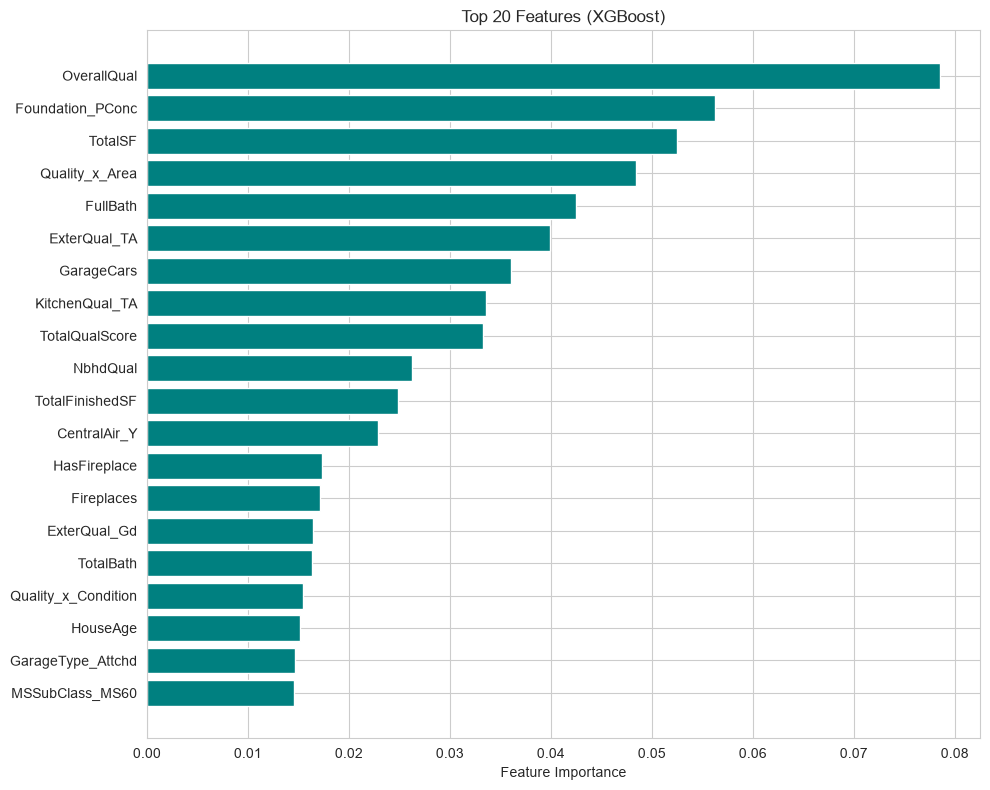


Hər ikisində ilk 20-də olanlar (11 ədəd):
   CentralAir_Y
   Foundation_PConc
   GarageCars
   HouseAge
   NbhdQual
   Quality_x_Area
   Quality_x_Condition
   TotalBath
   TotalFinishedSF
   TotalQualScore
   TotalSF

Yalnız XGBoost-da: ['ExterQual_Gd', 'ExterQual_TA', 'Fireplaces', 'FullBath', 'GarageType_Attchd', 'HasFireplace', 'KitchenQual_TA', 'MSSubClass_MS60', 'OverallQual']
Yalnız Lasso-da:   ['BsmtExposure_Gd', 'Exterior1st_BrkFace', 'MSZoning_FV', 'MSZoning_RL', 'Neighborhood_Crawfor', 'RemodAge', 'SaleCondition_Normal', 'SaleType_New', 'Slope_to_LotArea']


In [24]:
# TODO: XGBoost-dan xüsusiyyət əhəmiyyətini çıxarın
# - xgb.fit(X_train, y_train)  (əgər hələ öyrədilməyibsə)
# - importance = pd.DataFrame({
#       'Feature': X_train.columns,
#       'Importance': xgb.feature_importances_
#   }).sort_values('Importance', ascending=False)
best_xgb_model = grid_XGB.best_estimator_ 
importance = pd.DataFrame({
    "Feature" : X_train.columns,
    "Importance":  best_xgb_model.feature_importances_
}).sort_values("Importance" , ascending = False).reset_index(drop=True)
print(importance.head(20).to_string(index=False))


# TODO: Ən vacib ilk 20 xüsusiyyəti qrafikdə göstərin
# - plt.figure(figsize=(10, 8))
# - top20 = importance.head(20)
# - plt.barh(top20['Feature'], top20['Importance'], color='teal')
# - plt.xlabel('Feature Importance')
# - plt.title('Top 20 Features (XGBoost)')
# - plt.gca().invert_yaxis()  (ən yüksək əhəmiyyət yuxarıda olsun)
# - plt.tight_layout()
# - plt.show()

top20 = importance.head(20)
plt.figure(figsize=(10, 8))
plt.barh(top20['Feature'], top20['Importance'], color='teal')
plt.xlabel('Feature Importance')
plt.title('Top 20 Features (XGBoost)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# TODO: Lasso-nun xüsusiyyət seçimi ilə müqayisə edin
# - Hansı xüsusiyyətlər həm XGBoost-da, həm də Lasso-da vacib görünür?
# - Kəsişməni (overlap) çap edin

lasso_coef = pd.Series(best_lasso.coef_, index=X_train.columns)
lasso_top20 = set(lasso_coef.abs().sort_values(ascending=False).head(20).index)
xgb_top20 = set(top20['Feature'])
overlap = xgb_top20 & lasso_top20

print(f"\nHər ikisində ilk 20-də olanlar ({len(overlap)} ədəd):")
for f in sorted(overlap):
    print("  ", f)
print("\nYalnız XGBoost-da:", sorted(xgb_top20 - lasso_top20))
print("Yalnız Lasso-da:  ", sorted(lasso_top20 - xgb_top20))

---
## BONUS Tapşırıq 2: GridSearchCV ilə Hiperparametr Tənzimlənməsi

Daha da yaxşı performans üçün ən yaxşı modeli dəqiqləşdirin.

In [25]:
# TODO: GridSearchCV idxal edin
# - from sklearn.model_selection import GridSearchCV

# TODO: LightGBM (və ya XGBoost) üçün parametr şəbəkəsi (grid) təyin edin
# - param_grid = {
#       'n_estimators': [1000, 2000, 3000],
#       'learning_rate': [0.01, 0.05, 0.1],
#       'max_depth': [3, 4, 5],
#       'num_leaves': [15, 31, 63],
#   }
#

param_grid = {
    'n_estimators': [1000, 2000, 3000],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'num_leaves': [15, 31, 63],
}

grid_search = GridSearchCV(
    LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1),
    param_grid,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    verbose=1
)

grid_search.fit(X_train , y_train)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")



# Qeyd: Bu şəbəkədə 3*3*3*3 = 81 kombinasiya × 5 qat = 405 model təlimi var
# Çox yavaş olarsa, şəbəkəni kiçildin və ya əvəzinə RandomizedSearchCV istifadə edin

# TODO: GridSearchCV-ni işə salın
# - grid_search = GridSearchCV(
#       LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1),
#       param_grid,
#       cv=kf,
#       scoring='neg_root_mean_squared_error',
#       verbose=1
#   )
# - grid_search.fit(X_train, y_train)

# TODO: Ən yaxşı parametrləri və nəticəni çap edin
# - print(f"Best Parameters: {grid_search.best_params_}")
# - print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")

# TODO: Tənzimlənmiş modeli blend-ə daxil edin və yenidən qiymətləndirin

best_enet.fit(X_train_scaled, y_train)
best_lasso.fit(X_train_scaled, y_train)

pred_enet = best_enet.predict(X_test_scaled)
pred_lasso = best_lasso.predict(X_test_scaled)
pred_xgb = grid_XGB.predict(X_test)
pred_lgb_new = grid_search.predict(X_test)      # şablon şəbəkəsi ilə tənzimlənmiş LightGBM

pred_blend_new = 0.2 * pred_enet + 0.2 * pred_lasso + 0.3 * pred_xgb + 0.3 * pred_lgb_new

print(f"Blend (yeni LightGBM) RMSE: {np.sqrt(mean_squared_error(y_test, pred_blend_new)):.4f}, "
    f"R²: {r2_score(y_test, pred_blend_new):.4f}")
print("Əvvəlki blend: RMSE: 0.1168, R²: 0.9191")


Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 2000, 'num_leaves': 15}
Best CV RMSE: 0.1175
Blend (yeni LightGBM) RMSE: 0.1167, R²: 0.9193
Əvvəlki blend: RMSE: 0.1168, R²: 0.9191


---
## BONUS Tapşırıq 3: Stacking (Qabaqcıl Ansambl)

Stacking sadə ortalamadan kənara çıxır: baza model proqnozlarını birləşdirməyin optimal yolunu öyrənən **meta-model** öyrədir.

```
Baza Modellər:        Meta-Model:
Ridge    → pred_1 ─┐
Lasso    → pred_2 ─┤→ LinearRegression → yekun proqnoz
XGBoost  → pred_3 ─┤
LightGBM → pred_4 ─┘
```


In [26]:
# TODO: StackingRegressor idxal edin
# - from sklearn.ensemble import StackingRegressor

# TODO: Stacking ansamblını yaradın
# - stacker = StackingRegressor(
#       estimators=[
#           ('ridge', best_ridge),
#           ('lasso', best_lasso),
#           ('xgb', xgb),
#           ('lgbm', lgbm)
#       ],
#       final_estimator=Ridge(alpha=10.0),  # meta-model
#       cv=kf
#   )


enet_pipe = make_pipeline(StandardScaler() , best_enet)
lasso_pipe = make_pipeline(StandardScaler() , best_lasso)


stacker = StackingRegressor(estimators=[
    ("enet" , enet_pipe) , 
    ("lasso" , lasso_pipe) , 
    ("xgb" , grid_XGB.best_estimator_),
    ("lgbm" , grid_lgb.best_estimator_)
] , final_estimator=Ridge(alpha=10.0),cv=kf)

# Qeyd: stacker xətti baza modellər üçün miqyaslanmış, ağaclar üçün miqyaslanmamış verilənlərdən istifadə edir.
# StackingRegressor bütün qiymətləndiricilərə (estimators) eyni verilənləri ötürdüyü üçün,
# burada yalnız ağac modellərindən istifadə etmək və ya miqyaslama üçün Pipeline istifadə etmək istəyə bilərsiniz.
# Alternativ olaraq, Tapşırıq 10-dakı sadə blending yanaşmasından istifadə edin.

# TODO: Stacker-i qiymətləndirin
# - scores = rmse_cv(stacker, X_train, y_train)
# - print(f"Stacking RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")
# - Tapşırıq 10-dakı sadə blending ilə müqayisə edin

scores = rmse_cv(stacker, X_train, y_train)
results['Stacking'] = scores
print(f"Stacking RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})")

stacker.fit(X_train, y_train)
pred_stack = stacker.predict(X_test)

print(f"\nStacking test RMSE: {np.sqrt(mean_squared_error(y_test, pred_stack)):.4f}, "
    f"R²: {r2_score(y_test, pred_stack):.4f}")
print("Sadə blend test RMSE: 0.1168, R²: 0.9191")

print("Meta-model çəkiləri:", stacker.final_estimator_.coef_.round(3))

Stacking RMSE: 0.1089 (+/- 0.0100)

Stacking test RMSE: 0.1169, R²: 0.9189
Sadə blend test RMSE: 0.1168, R²: 0.9191
Meta-model çəkiləri: [0.24  0.241 0.261 0.256]


In [27]:
stacker.fit(X_train, y_train)
pred_tr = stacker.predict(X_train)
pred_te = stacker.predict(X_test)

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R²': r2_score(y_true, y_pred)}

# 1) Log miqyasında (modelin öyrəndiyi miqyas)
log_tbl = pd.DataFrame({'Təlim': metrics(y_train, pred_tr),
                        'Test': metrics(y_test, pred_te)})
print("LOG miqyası:\n", log_tbl.round(4), "\n")

# 2) Dollarla (real mənası)
usd_tbl = pd.DataFrame({'Təlim': metrics(np.expm1(y_train), np.expm1(pred_tr)),
                        'Test': metrics(np.expm1(y_test), np.expm1(pred_te))})
print("DOLLAR miqyası:\n", usd_tbl.round(2), "\n")

# 3) Dürüst təlim qiymətləndirməsi: out-of-fold proqnozlar
oof = cross_val_predict(stacker, X_train, y_train, cv=kf)   # yavaş ola bilər
print("OOF (CV) metrikləri:", {k: round(v, 4) for k, v in metrics(y_train, oof).items()}, "\n")

# 4) Overfitting göstəriciləri
print(f"R² fərqi (təlim - test): {log_tbl.loc['R²','Təlim'] - log_tbl.loc['R²','Test']:.4f}")
print(f"RMSE nisbəti (test / OOF): {log_tbl.loc['RMSE','Test'] / metrics(y_train, oof)['RMSE']:.3f}")

# 5) Qalıqlar (test, dollar)
res = np.expm1(y_test) - np.expm1(pred_te)
print(f"\nQalıq ortası: {res.mean():,.0f} | std: {res.std():,.0f} | min: {res.min():,.0f} | max: {res.max():,.0f}")
print(f"Faiz səhvi (MAPE): {(np.abs(res) / np.expm1(y_test)).mean() * 100:.1f}%")

LOG miqyası:
        Təlim    Test
MSE   0.0058  0.0137
RMSE  0.0764  0.1169
MAE   0.0540  0.0756
R²    0.9629  0.9189 

DOLLAR miqyası:
              Təlim          Test
MSE   1.930599e+08  3.287747e+08
RMSE  1.389460e+04  1.813215e+04
MAE   9.356880e+03  1.278924e+04
R²    9.700000e-01  9.400000e-01 

OOF (CV) metrikləri: {'MSE': 0.012, 'RMSE': np.float64(0.1094), 'MAE': 0.074, 'R²': 0.924} 

R² fərqi (təlim - test): 0.0440
RMSE nisbəti (test / OOF): 1.069

Qalıq ortası: 471 | std: 18,157 | min: -66,016 | max: 74,117
Faiz səhvi (MAPE): 7.9%


In [30]:
weights = [0.2, 0.2, 0.3, 0.3]   # enet, lasso, xgb, lgb

models = {
    'enet':  make_pipeline(StandardScaler(), clone(best_enet)),
    'lasso': make_pipeline(StandardScaler(), clone(best_lasso)),
    'xgb':   clone(grid_XGB.best_estimator_),
    'lgb':   clone(grid_lgb.best_estimator_),
}

fold_rmse = []
for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    preds = []
    for name, m in models.items():
        m.fit(X_tr, y_tr)
        preds.append(m.predict(X_val))

    blend_val = np.average(preds, axis=0, weights=weights)
    r = np.sqrt(mean_squared_error(y_val, blend_val))
    fold_rmse.append(r)
    print(f"Qat {fold}: Blend RMSE = {r:.4f}")

fold_rmse = np.array(fold_rmse)
results['Blend'] = fold_rmse
print(f"\nBlend CV RMSE: {fold_rmse.mean():.4f} (+/- {fold_rmse.std():.4f})")

Qat 1: Blend RMSE = 0.1245
Qat 2: Blend RMSE = 0.1037
Qat 3: Blend RMSE = 0.0965
Qat 4: Blend RMSE = 0.1034
Qat 5: Blend RMSE = 0.1157

Blend CV RMSE: 0.1088 (+/- 0.0100)


In [31]:
print("test_ids sayı:", len(test_ids))
print("X_kaggle forma:", X_kaggle.shape)
print("İlk Id-lər:", test_ids.head().tolist())

test_ids sayı: 1459
X_kaggle forma: (1459, 250)
İlk Id-lər: [1461, 1462, 1463, 1464, 1465]


---
## Təqdimat Yoxlama Siyahısı

Notebook-unuzun aşağıdakıları ehtiva etdiyindən əmin olun:

- ✓ Bütün tələb olunan kitabxanalar idxal edilib (xgboost, lightgbm daxil olmaqla)
- ✓ Verilənlər loqarifmik transformasiya olunmuş hədəflə yüklənib
- ✓ Xüsusiyyətlər ön işlənib (kodlaşdırılıb, miqyaslanıb, çatışmayan dəyər yoxdur)
- ✓ Çarpaz yoxlama çərçivəsi qurulub və ardıcıl istifadə olunub
- ✓ Ridge, Lasso, ElasticNet alpha tənzimlənməsi ilə öyrədilib
- ✓ Random Forest öyrədilib
- ✓ XGBoost düzgün hiperparametrlərlə öyrədilib
- ✓ LightGBM düzgün hiperparametrlərlə öyrədilib
- ✓ Bütün modellər cədvəldə və qrafikdə müqayisə edilib
- ✓ Modellər optimallaşdırılmış çəkilərlə birləşdirilib
- ✓ Kaggle təqdimat faylı yaradılıb (submission_advanced.csv)
- ✓ Bütün refleksiya sualları cavablandırılıb
- ✓ Notebook boyunca aydın sənədləşdirmə və şərhlər mövcuddur

## Əsas Nəticələr

1. Kaggle RMSLE qiymətləndirməsindən istifadə etdikdə **hədəfin loqarifmik transformasiyası** vacibdir
2. **Reqlyarizasiya** (Ridge/Lasso) çoxlu xüsusiyyət olduqda overfitting-in qarşısını alır
3. **Lasso** həm də xüsusiyyət seçicisi kimi çıxış edir — 200+ xüsusiyyətinizdən hansıların həqiqətən vacib olduğunu deyir
4. **Ağac əsaslı modellər** (XGBoost, LightGBM) xətti modellərin əsaslı şəkildə tuta bilmədiyi qeyri-xətti qanunauyğunluqları tutur
5. **Çarpaz yoxlama** etibarsız tək bölgülü qiymətləndirməni əvəz edir
6. **Modellərin birləşdirilməsi (blending)** rəqabətli ML-də ən effektiv tək üsuldur
7. **Heç bir tək model həmişə ən yaxşı deyil** — ansamblın gücü ondadır ki, fərqli modellər bir-birinin zəifliklərini kompensasiya edir